# 02 · Análisis descriptivo de los datos de NASA POWER

Zona piloto anónima (centro de celda de datos, Curicó, Maule) · 1991–2026 · diario.

Responde, para cada variable: **¿cómo se distribuye?, ¿cuál es su ciclo anual?, ¿qué cambió en el evento de primavera 2026 (21-sep a 20-oct) y cuánto?**
La lógica vive en `src/descriptivo.py` y `src/anomalia.py`; aquí solo se orquesta y se grafica.

**Notas de validez:** NASA POWER es un reanálisis de grilla gruesa (~50 km), no una estación; la lluvia no es normal, por eso se usa ranking empírico; la humedad de suelo (`GWET*`) es un índice 0–1 modelado, no una medición. Todo es descriptivo: aún no es un modelo de riesgo.

In [1]:
import os, sys, pathlib
raiz = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
os.chdir(raiz); sys.path.insert(0, str(raiz))   # para importar src/ y usar data/cache

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from src import anonimato, descriptivo as ds
from src.anomalia import descargar_historico, curva_acumulada, _mascara_ventana, ANIOS_ANALOGOS, VENTANA_EVENTO

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25})
pd.options.display.float_format = "{:,.2f}".format

ANIO = 2026
FOCO = (pd.Timestamp("2026-10-05"), pd.Timestamp("2026-10-13"))   # semana de foco (propuesta)
VENT = (pd.Timestamp("2026-09-21"), pd.Timestamp("2026-10-20"))
PARAMS = ("T2M", "T2M_MAX", "T2M_MIN", "RH2M", "PRECTOTCORR", "GWETROOT", "GWETTOP")

## 1 · Carga y calidad de los datos

In [2]:
pt = anonimato.generalizar()
df = descargar_historico(pt.lat, pt.lon, 1991, ANIO, params=PARAMS)
print(f"Centro de celda: {pt.lat}, {pt.lon}")
print(f"{len(df):,} días · {df.index.min().date()} → {df.index.max().date()} · {df.index.year.nunique()} años")
dias_esperados = (df.index.max() - df.index.min()).days + 1
print(f"Días faltantes en el calendario: {dias_esperados - len(df)} · valores NaN: {int(df.isna().sum().sum())}")
print("Último dato disponible:", df.index.max().date(), "(POWER tiene unos días de rezago)")
df.tail(3)

Centro de celda: -35.0, -71.25
13,096 días · 1991-01-01 → 2026-11-08 · 36 años
Días faltantes en el calendario: 0 · valores NaN: 0
Último dato disponible: 2026-11-08 (POWER tiene unos días de rezago)


,T2M,T2M_MAX,T2M_MIN,RH2M,PRECTOTCORR,GWETROOT,GWETTOP
fecha,,,,,,,
2026-11-06,11.62,15.86,8.54,70.92,1.57,0.72,0.66
2026-11-07,16.72,23.81,6.99,56.77,0.00,0.71,0.64
2026-11-08,21.29,28.37,12.51,55.66,0.00,0.70,0.61


## 2 · Resumen estadístico por variable (toda la serie)

In [3]:
ds.resumen_variables(df)

,n,faltantes_%,min,p5,p25,mediana,media,p75,p95,max,desv,asimetria
Temperatura media (°C),13096,0.00,0.23,7.14,11.26,15.50,15.74,20.54,24.27,29.46,5.51,0.00
Temperatura máxima (°C),13096,0.00,3.77,11.63,17.64,23.63,23.57,29.96,34.62,42.70,7.36,-0.11
Temperatura mínima (°C),13096,0.00,-4.03,2.79,6.70,9.75,9.63,12.83,15.80,20.28,4.03,-0.21
Humedad relativa (%),13096,0.00,7.51,25.89,40.14,53.45,54.57,68.25,87.52,99.18,18.69,0.20
Lluvia (mm/día),13096,0.00,0.00,0.00,0.00,0.00,1.19,0.25,7.10,67.98,4.19,6.22
Humedad zona radicular (0-1),13096,0.00,0.58,0.58,0.59,0.61,0.66,0.70,0.90,1.00,0.10,1.53
Humedad superficial (0-1),13096,0.00,0.15,0.19,0.27,0.56,0.51,0.69,0.90,1.00,0.23,0.05


La **asimetría** positiva alta de la lluvia confirma que no es normal (muchos días secos y pocos muy lluviosos): por eso se reporta el ranking y no solo el z-score.

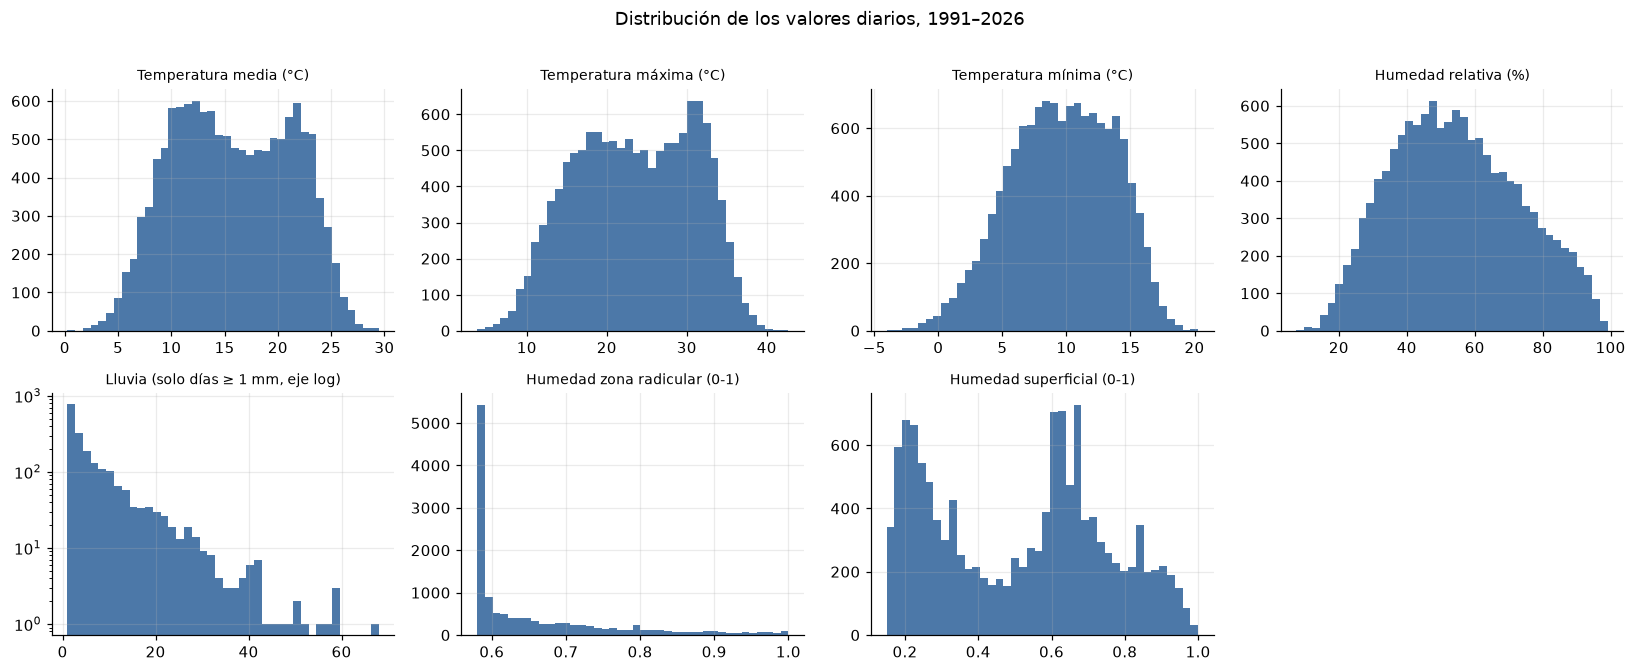

In [4]:
fig, axs = plt.subplots(2, 4, figsize=(15, 6))
for ax, c in zip(axs.ravel(), PARAMS):
    x = df[c].dropna()
    if c == "PRECTOTCORR":
        x = x[x >= ds.UMBRAL_DIA_LLUVIOSO]; ax.set_yscale("log")
        ax.set_title("Lluvia (solo días ≥ 1 mm, eje log)", fontsize=9)
    else:
        ax.set_title(ds.NOMBRES[c], fontsize=9)
    ax.hist(x, bins=40, color="#4C78A8")
axs.ravel()[-1].axis("off")
fig.suptitle("Distribución de los valores diarios, 1991–2026", y=1.01); plt.tight_layout()

In [5]:
llu = df["PRECTOTCORR"]
print(f"Días con lluvia ≥ 1 mm: {(llu >= 1).mean():.0%} · ≥ 10 mm: {(llu >= 10).mean():.1%} · ≥ 30 mm: {(llu >= 30).mean():.2%}")
print("Mayores lluvias diarias de la serie (mm):")
print(llu.nlargest(8).round(1).to_string())

Días con lluvia ≥ 1 mm: 16% · ≥ 10 mm: 3.5% · ≥ 30 mm: 0.41%
Mayores lluvias diarias de la serie (mm):
fecha
1992-06-05   68.00
2000-06-12   59.20
1992-06-04   58.90
1997-06-11   58.80
1992-05-24   57.00
2026-10-06   54.80
1992-05-05   52.20
2002-05-25   50.30


## 3 · Ciclo anual: ¿cómo se compara 2026 con un año típico?
Línea = promedio mensual 1991–2025; banda = percentiles 10–90 entre años; puntos = 2026 (el último mes está **parcial**: los datos llegan hasta principios de noviembre).

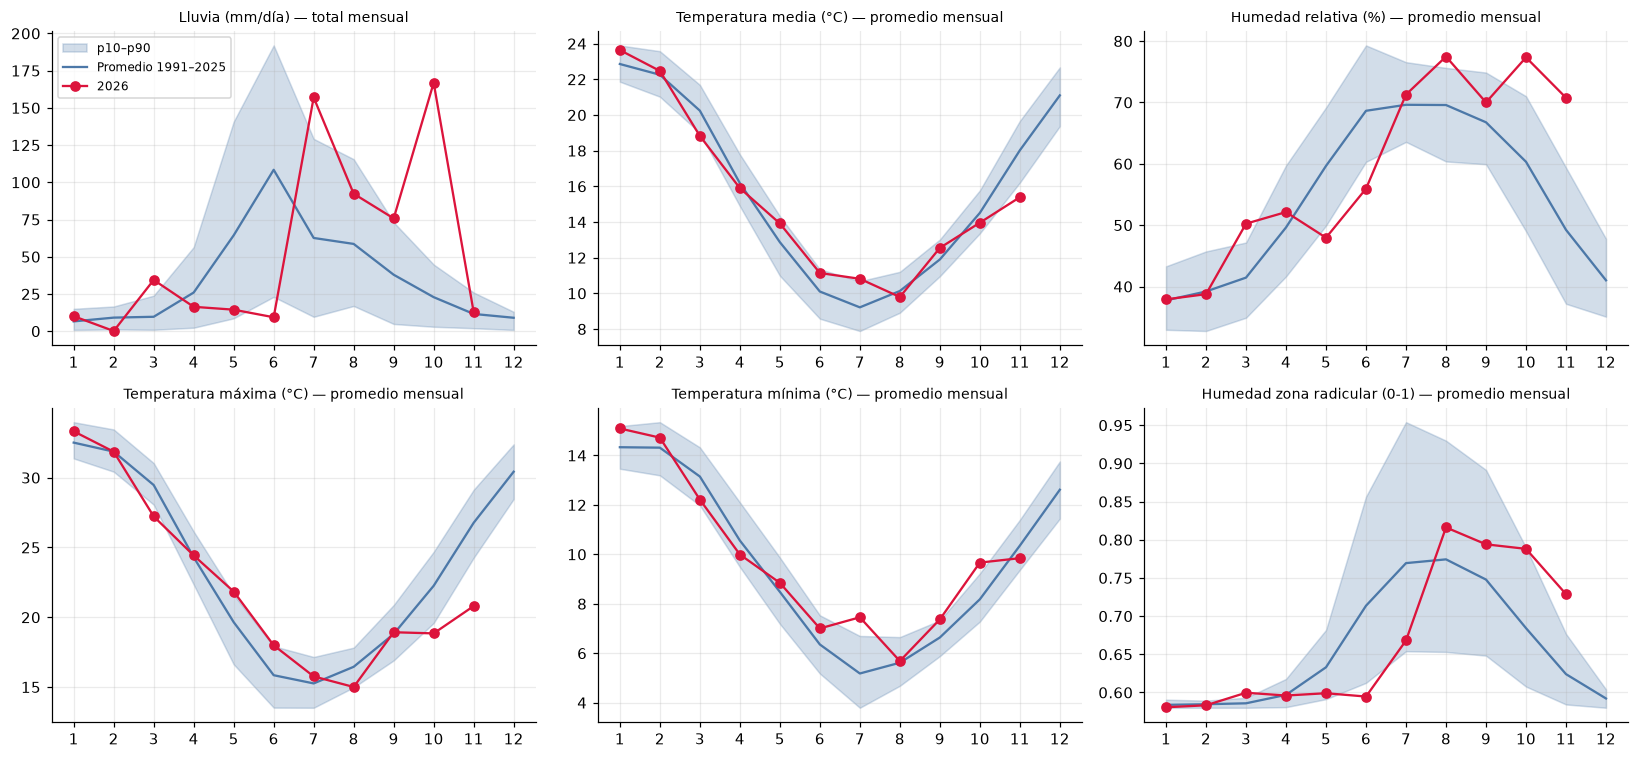

In [6]:
fig, axs = plt.subplots(2, 3, figsize=(15, 7))
meses = np.arange(1, 13)
for ax, c in zip(axs.ravel(), ["PRECTOTCORR", "T2M", "RH2M", "T2M_MAX", "T2M_MIN", "GWETROOT"]):
    cl = ds.climatologia_mensual(df, c, 1991, ANIO - 1)
    a = ds.mensual_de_un_anio(df, c, ANIO)
    ax.fill_between(meses, cl["p10"], cl["p90"], alpha=.25, color="#4C78A8", label="p10–p90")
    ax.plot(meses, cl["media"], color="#4C78A8", label="Promedio 1991–2025")
    ax.plot(a.index, a.values, "o-", color="crimson", label=str(ANIO))
    ax.set_title(ds.NOMBRES[c] + (" — total mensual" if c == "PRECTOTCORR" else " — promedio mensual"), fontsize=9)
    ax.set_xticks(meses)
axs[0, 0].legend(fontsize=8); plt.tight_layout()

## 4 · El evento: ventana 21-sep a 20-oct, 2026 frente a 1991–2025
Para cada indicador: promedio de la base, valor 2026, diferencia, puesto (1 = el más alto) y percentil.

In [7]:
tabla = ds.tabla_ventana(df, ANIO)
tabla

,base 1991-2025,2026,dif_abs,dif_%,puesto,percentil
indicador,,,,,,
Lluvia acumulada (mm),23.67,125.97,102.30,432.12,2 de 36,97.14
Lluvia máxima diaria (mm),8.10,54.79,46.69,576.06,1 de 36,100.00
Días con lluvia ≥ 1 mm,4.26,15.00,10.74,252.35,1 de 36,100.00
Temperatura media (°C),13.52,13.01,-0.51,-3.77,25 de 36,31.43
Temperatura máxima media (°C),21.00,18.02,-2.98,-14.21,34 de 36,5.71
Temperatura mínima media (°C),7.56,8.76,1.20,15.87,2 de 36,97.14
Humedad relativa media (%),63.00,77.30,14.30,22.70,2 de 36,97.14
Días con HR ≥ 90 %,0.26,1.00,0.74,288.89,3 de 36,90.00
Humedad radicular media (0-1),0.71,0.79,0.08,11.85,8 de 36,80.00


Cómo leerla: `dif_abs` es la diferencia en la unidad de la variable (usar esta para temperatura; `dif_%` sobre °C no es interpretable). Un puesto entre los primeros de 36 indica un valor de los más altos de la serie, pero **la grilla de 50 km y la naturaleza modelada de las variables de suelo limitan cuánto se puede afirmar** a escala de predio.

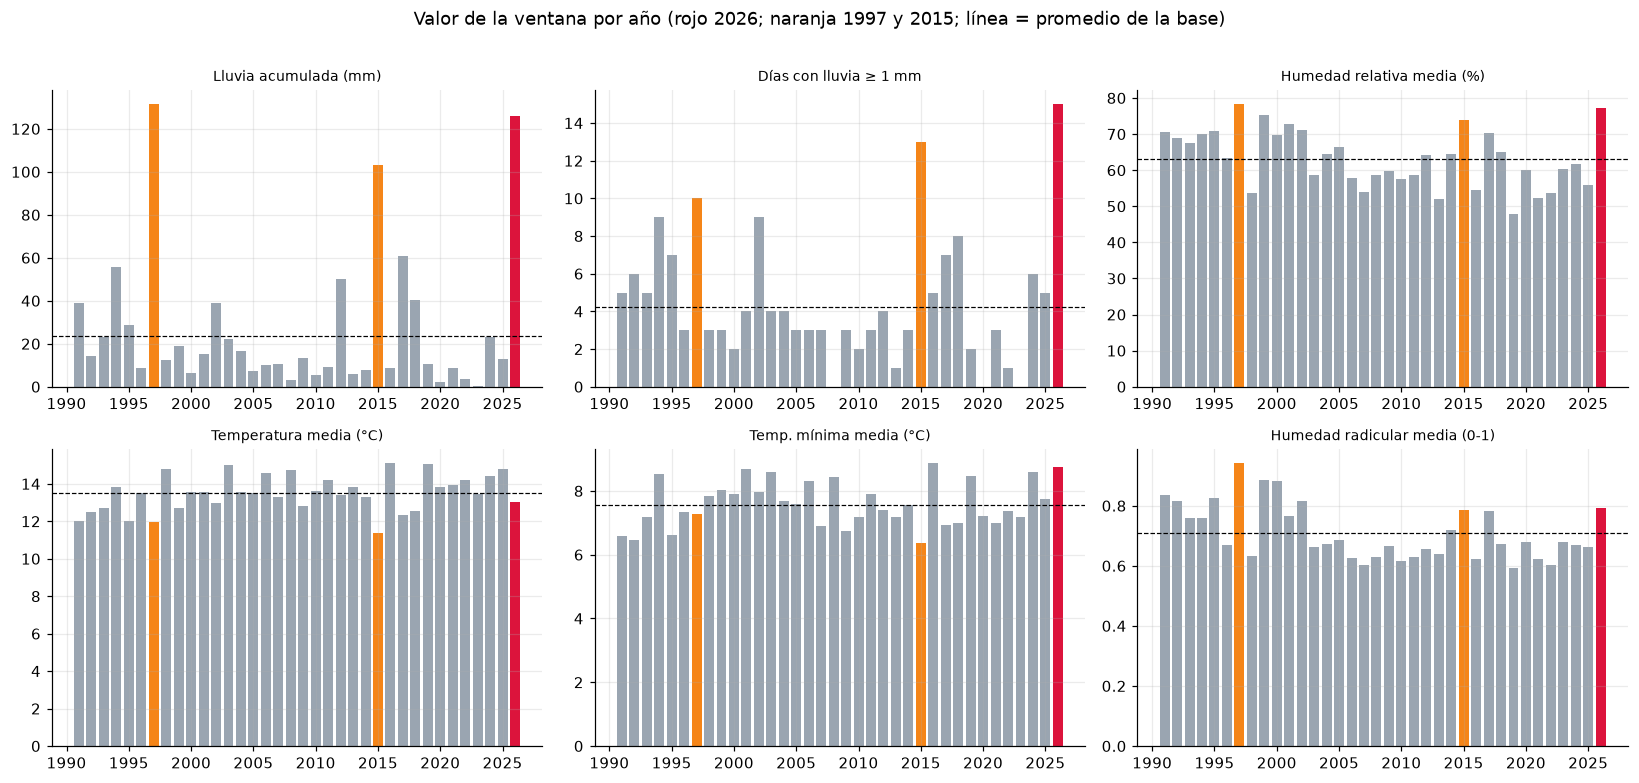

In [8]:
claves = [("PRECTOTCORR", "sum", "Lluvia acumulada (mm)"), ("DIAS_LLUVIA", "sum", "Días con lluvia ≥ 1 mm"),
          ("RH2M", "mean", "Humedad relativa media (%)"), ("T2M", "mean", "Temperatura media (°C)"),
          ("T2M_MIN", "mean", "Temp. mínima media (°C)"), ("GWETROOT", "mean", "Humedad radicular media (0-1)")]
fig, axs = plt.subplots(2, 3, figsize=(15, 7))
for ax, (c, ag, et) in zip(axs.ravel(), claves):
    s = ds.series_ventana(df, c, ag)
    col = ["crimson" if a == ANIO else "#F58518" if a in ANIOS_ANALOGOS else "#9AA5B1" for a in s.index]
    ax.bar(s.index, s.values, color=col)
    ax.axhline(s[s.index != ANIO].mean(), color="k", lw=.8, ls="--")
    ax.set_title(et, fontsize=9)
fig.suptitle("Valor de la ventana por año (rojo 2026; naranja 1997 y 2015; línea = promedio de la base)", y=1.01)
plt.tight_layout()

### 4.1 Lluvia acumulada día a día

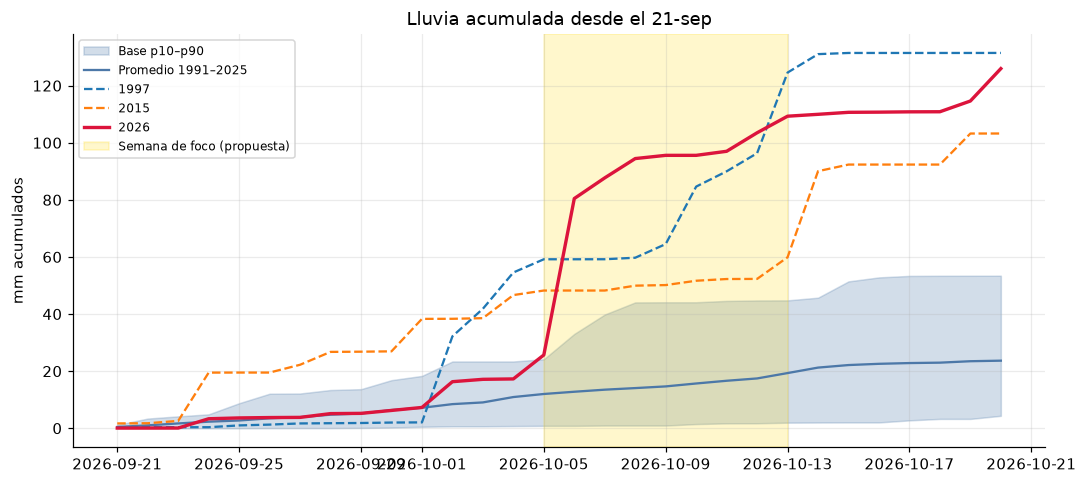

In [9]:
cur = curva_acumulada(df, ANIO)
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.fill_between(cur.index, cur["p10"], cur["p90"], alpha=.25, color="#4C78A8", label="Base p10–p90")
ax.plot(cur.index, cur["promedio"], color="#4C78A8", label="Promedio 1991–2025")
for a in ANIOS_ANALOGOS:
    ax.plot(cur.index, cur[str(a)], ls="--", label=str(a))
ax.plot(cur.index, cur["actual"], color="crimson", lw=2.2, label=str(ANIO))
ax.axvspan(FOCO[0], FOCO[1], color="gold", alpha=.2, label="Semana de foco (propuesta)")
ax.set_ylabel("mm acumulados"); ax.legend(fontsize=8); ax.set_title("Lluvia acumulada desde el 21-sep"); plt.tight_layout()

## 5 · La serie diaria de la primavera 2026

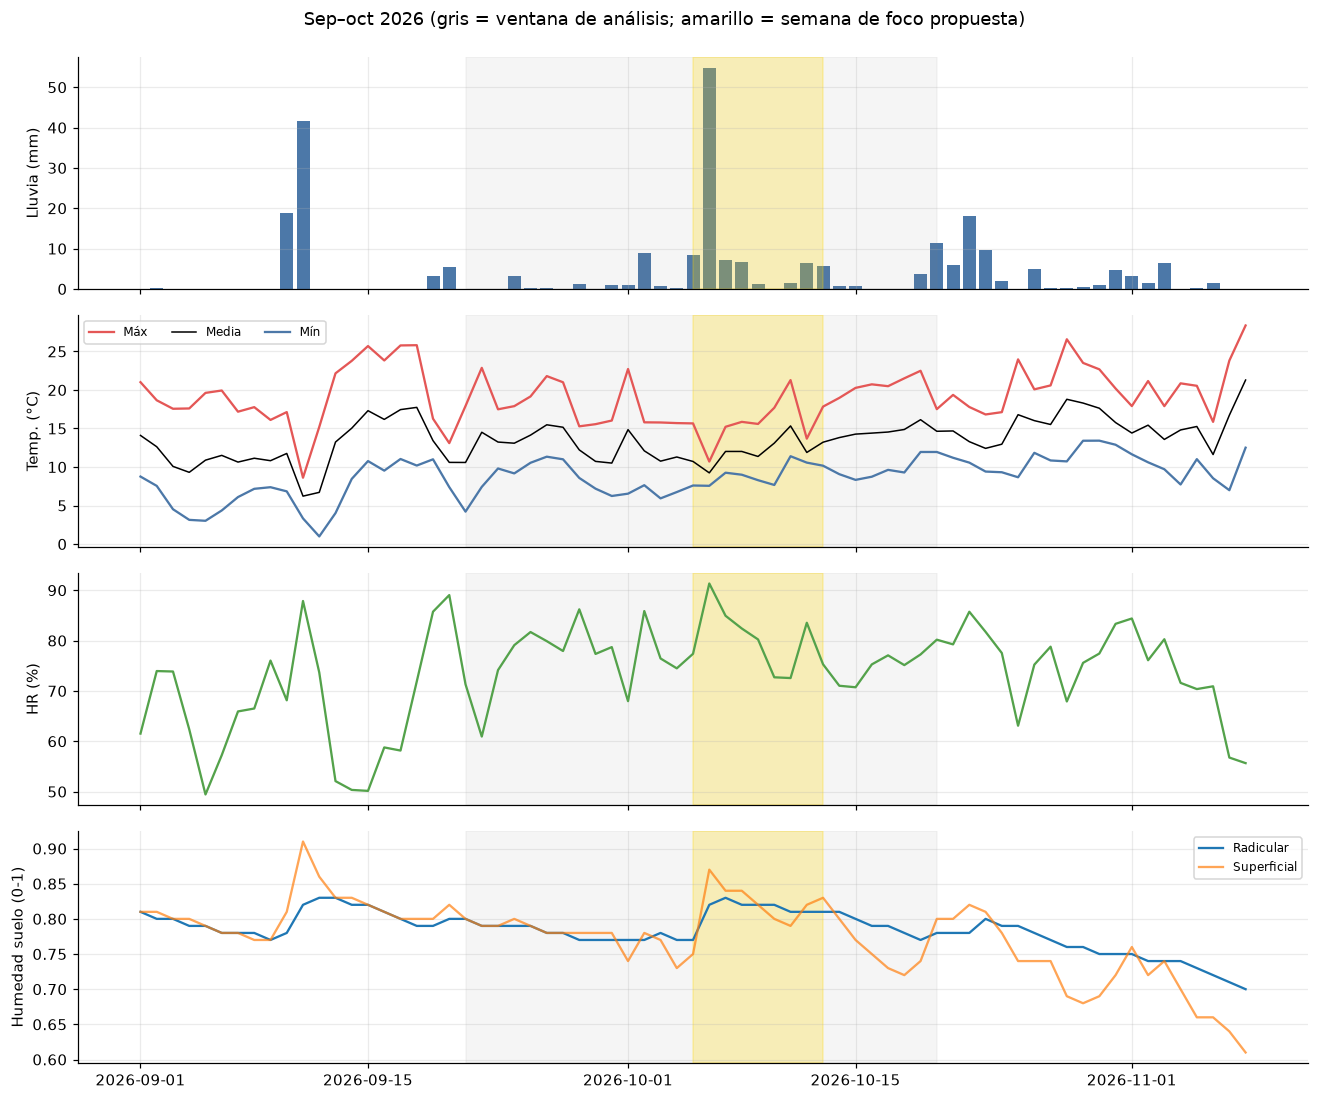

In [10]:
p = df.loc["2026-09-01":]
fig, axs = plt.subplots(4, 1, figsize=(12, 10), sharex=True)
axs[0].bar(p.index, p["PRECTOTCORR"], color="#4C78A8"); axs[0].set_ylabel("Lluvia (mm)")
axs[1].plot(p.index, p["T2M_MAX"], color="#E45756", label="Máx"); axs[1].plot(p.index, p["T2M"], color="k", lw=1, label="Media")
axs[1].plot(p.index, p["T2M_MIN"], color="#4C78A8", label="Mín"); axs[1].set_ylabel("Temp. (°C)"); axs[1].legend(ncol=3, fontsize=8)
axs[2].plot(p.index, p["RH2M"], color="#54A24B"); axs[2].set_ylabel("HR (%)")
axs[3].plot(p.index, p["GWETROOT"], label="Radicular"); axs[3].plot(p.index, p["GWETTOP"], label="Superficial", alpha=.7)
axs[3].set_ylabel("Humedad suelo (0-1)"); axs[3].legend(fontsize=8)
for ax in axs:
    ax.axvspan(*VENT, color="grey", alpha=.08); ax.axvspan(*FOCO, color="gold", alpha=.25)
fig.suptitle("Sep–oct 2026 (gris = ventana de análisis; amarillo = semana de foco propuesta)", y=0.995); plt.tight_layout()

In [11]:
foco = df.loc[FOCO[0]:FOCO[1]]
print(f"Semana de foco {FOCO[0].date()} → {FOCO[1].date()}")
print(f"Lluvia total: {foco['PRECTOTCORR'].sum():.0f} mm · máximo diario: {foco['PRECTOTCORR'].max():.0f} mm el {foco['PRECTOTCORR'].idxmax().date()}")
print(f"Temp. media {foco['T2M'].mean():.1f} °C · HR media {foco['RH2M'].mean():.0f} % · días con HR ≥ 90 %: {(foco['RH2M'] >= 90).sum()}")
# Cuántas veces, en cualquier época de 1991-2025, 9 días seguidos acumularon tanta lluvia
r9 = df["PRECTOTCORR"].rolling(9).sum()
r9_hist = r9[r9.index.year < ANIO].dropna()
x = foco["PRECTOTCORR"].sum()
print(f"Sumas móviles de 9 días >= {x:.0f} mm en 1991–2025: {(r9_hist >= x).sum()} de {len(r9_hist):,} ventanas")

Semana de foco 2026-10-05 → 2026-10-13
Lluvia total: 92 mm · máximo diario: 55 mm el 2026-10-06
Temp. media 12.1 °C · HR media 80 % · días con HR ≥ 90 %: 1
Sumas móviles de 9 días >= 92 mm en 1991–2025: 167 de 12,776 ventanas


## 6 · Relaciones entre variables (días de la ventana, todos los años)

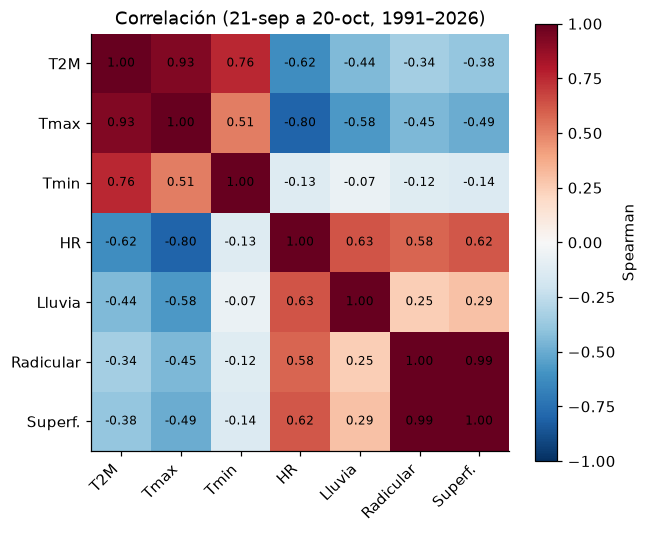

In [12]:
v = df.loc[_mascara_ventana(df.index, *VENTANA_EVENTO), list(PARAMS)]
corr = v.corr(method="spearman")
corr.index = corr.columns = ["T2M", "Tmax", "Tmin", "HR", "Lluvia", "Radicular", "Superf."]
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1); ax.grid(False)
ax.set_xticks(range(7)); ax.set_xticklabels(corr.columns, rotation=45, ha="right"); ax.set_yticks(range(7)); ax.set_yticklabels(corr.columns)
for i in range(7):
    for j in range(7):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
plt.colorbar(im, ax=ax, label="Spearman"); ax.set_title("Correlación (21-sep a 20-oct, 1991–2026)"); plt.tight_layout()

## 7 · ¿Hay tendencia de largo plazo en la lluvia de la ventana?
Descriptivo: Spearman entre año y lluvia de la ventana, sin 2026. **Cuidado al interpretar:** es una ventana de solo 30 días, con 35 años y una variable muy asimétrica dominada por pocos años extremos (1997, 2015). Una pendiente débil con p cercano a 0,05 no es evidencia sólida de cambio; se muestra como descripción, no como conclusión.

Spearman año–lluvia: rho = -0.35, p = 0.04
Pendiente de Theil–Sen: -0.43 mm/año (IC95% -0.81 a -0.03)
Normalidad de la lluvia de la ventana (Shapiro–Wilk): p = 0.0000


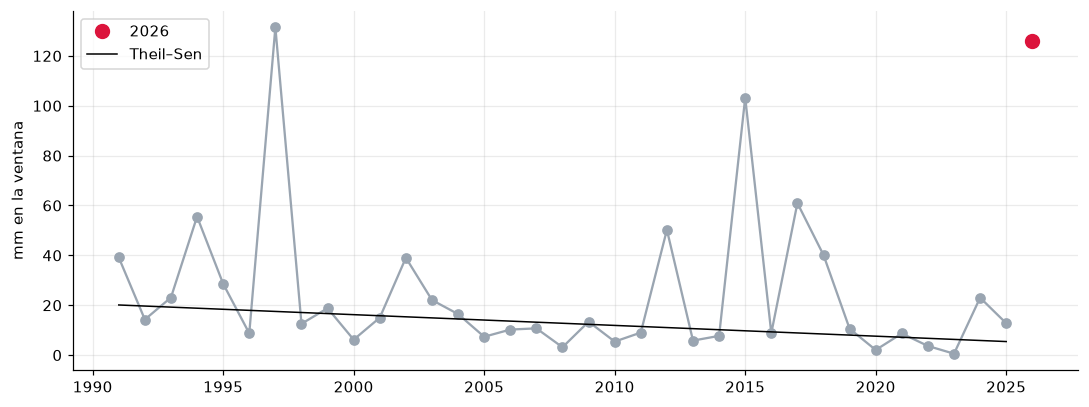

In [13]:
s = ds.series_ventana(df, "PRECTOTCORR", "sum")
b = s[s.index < ANIO]
rho, pval = stats.spearmanr(b.index, b.values)
pend = stats.theilslopes(b.values, b.index)
print(f"Spearman año–lluvia: rho = {rho:.2f}, p = {pval:.2f}")
print(f"Pendiente de Theil–Sen: {pend[0]:+.2f} mm/año (IC95% {pend[2]:+.2f} a {pend[3]:+.2f})")
print(f"Normalidad de la lluvia de la ventana (Shapiro–Wilk): p = {stats.shapiro(b.values).pvalue:.4f}")
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(b.index, b.values, "o-", color="#9AA5B1"); ax.plot(ANIO, s[ANIO], "o", color="crimson", ms=9, label=str(ANIO))
ax.plot(b.index, pend[1] + pend[0] * b.index, color="k", lw=1, label="Theil–Sen")
ax.set_ylabel("mm en la ventana"); ax.legend(); plt.tight_layout()

## 8 · Lectura y límites

**Qué muestran los datos (descriptivo, reanálisis NASA POWER):**
- El periodo 21-sep a 20-oct de 2026 fue de los más lluviosos de la serie: puesto 2 en lluvia acumulada y puesto 1 en lluvia máxima diaria y en días con lluvia.
- Fue también muy húmedo (humedad relativa media en el puesto 2) y con noches cálidas (mínima media en el puesto 2), pero con **máximas bajas** (puesto 34 de 36): un periodo nublado y fresco de día.
- La humedad de suelo subió, pero menos que la lluvia (radicular en el puesto 8): el promedio de la ventana no basta para el módulo de anegamiento.

**Límites:**
- Las cifras salen de **un reanálisis (NASA POWER)**, no de una estación: la comparación con la DMC (estación 340031) sigue pendiente y puede cambiar el puesto de 2026.
- `RH2M` y `T2M` se usarán para el modelo de *Botrytis* / *Monilinia*, que **aún no existe**: los umbrales de `src/risk.py` son placeholders. Aquí solo se describe el ambiente, no se estima riesgo.
- `GWETROOT` / `GWETTOP` son índices modelados; el módulo de anegamiento deberá validarse con SMAP.
- El granizo no se ve en estos datos.
- Los resultados son probabilísticos: describen qué tan inusual fue el periodo, no predicen un daño.